![Header](https://raw.githubusercontent.com/fabriciocarraro/EmbeddingGemma-2-Complete-Guide/refs/heads/main/images/header.png)

# EmbeddingGemma 2 - Complete Guide

> 🔁 **This is a port of the [Gemini Embedding 2 — Complete Guide](https://github.com/fabriciocarraro/Gemini-Embedding-2-Complete-Guide).** Same structure and same files, but running **EmbeddingGemma 2**, Google's *open-weights* (Apache 2.0) multimodal embedding model, **on your own machine**, with no API key. It is **not** a drop-in swap: wherever the two models behave differently (dimensions, prompts, audio/video input, PDFs), we stop and say so. You don't need the Gemini guide to follow this one.

## ✍️ Authors:

- Fabrício Carraro - [LinkedIn](https://www.linkedin.com/in/fabriciocarraro/) - Email: fabriciocarraro@gmail.com
- Pedro Gengo - [LinkedIn](https://www.linkedin.com/in/pedrogengo/) - Email: pedro.gengo.lourenco@gmail.com

## 🚀 Introduction

What if an image could find a sound? Or a voice clip could find a video? In the [Gemini Embedding 2 guide](https://github.com/fabriciocarraro/Gemini-Embedding-2-Complete-Guide) we did all of that through the Gemini API. The obvious follow-up question: **can an open model, small enough to run on a laptop, do the same?**

**EmbeddingGemma 2** is Google DeepMind's open multimodal embedding model. It maps **text (including code), images, audio, and video** (and combinations of them) into a single **768-dimensional** vector space. It has 740M parameters in total: a 270M text backbone plus a vision encoder (170M) and an audio encoder (300M) that you can load only when you need them. It runs locally, offline, and the weights are released under the Apache 2.0 license.

In this notebook we redo **every experiment** from that guide, in the same order (adjusting a couple of them where this model needed it): words and vector arithmetic, text clustering, images, an image search engine with FAISS, combined text + image embeddings, audio, video, documents, and Matryoshka dimensions. Along the way we keep score of what works out of the box, what needs an adaptation, and what doesn't carry over at all.

The notebook is meant to run in Google Colab with a GPU runtime, or locally with Python 3.11+ (it was executed end to end on a laptop GPU with 4 GB of VRAM). There is no API key: the first run downloads the model weights (~1.5 GB) from Hugging Face.

## 🔁 Gemini Embedding 2 → EmbeddingGemma 2: what changes?

| | **Gemini Embedding 2** (original guide) | **EmbeddingGemma 2** (this notebook) |
|---|---|---|
| How you run it | Gemini API (`google-genai`), API key, cloud | Open weights, runs locally (`sentence-transformers`), no key |
| License | Proprietary API | Apache 2.0 |
| Size | Not disclosed | 740M parameters (270M if you only need text) |
| Embedding size | 3,072 (MRL down to 128) | **768** (MRL: 512, 256, 128) |
| Context | 8,192 tokens of text | 8,192 tokens **shared by all modalities** in one input |
| Text | ✅ | ✅ (+ code), with **task prompts** recommended |
| Images | ✅ | ✅ (280 tokens per image by default) |
| Audio | ✅ native files (MP3, …) | ✅ native, but as a **16 kHz mono waveform** (we decode the MP3 first) |
| Video | ✅ up to 120 s, up to 32 frames, audio track ignored | ✅ frames sampled at 1 fps, up to 32 frames by default, audio track ignored (we use 280 tokens per frame instead of the default 140) |
| PDF | ✅ native, up to 6 pages | ❌ **not a supported input**. We render the pages as images (and compare with plain text extraction) |
| Mixing modalities | `types.Content(parts=[...])` | a dict: `{"text": "... <|image|>", "image": [...]}` |

And this is how each experiment from the original guide maps to this one:

| Section | Experiments | Status in this port |
|---|---|---|
| 📝 Text | first embedding, similarity matrix, word arithmetic, AG News clustering | ✅ same code, plus task prompts |
| 🖼️ Images | image ↔ words, image ↔ images, image arithmetic, FAISS image search | ✅ |
| 🧩 Combined | text + image posts, 6-image carousel in one embedding | ✅ via dict inputs |
| 🔊 Audio | text → audio, audio → audio, image → audio | ✅ after resampling to 16 kHz mono (image → audio is the model's weak spot here) |
| 🎬 Video | text → video, audio → video, video → video | ✅ (we decode the frames ourselves and raise the per-frame token budget, see why below) |
| 📄 PDF | text → PDF, audio → PDF, PDF → PDF | ⚠️ adapted: pages rendered as images |
| 📐 Dimensions | MRL truncation | ✅ 768 → 128 (instead of 3,072 → 128) |

"✅" here means *the experiment runs*. Whether the model gets the **answer** right is a different question, and we'll check that experiment by experiment (with a recap at the end).

## 📝 Text embeddings

First of all, we'll install and import the necessary libraries. EmbeddingGemma 2 needs recent versions of `transformers` and `sentence-transformers` (the model card asks for `sentence-transformers>=6.1.0`, which is the first version that keeps the order of multimodal inputs). In Colab, the cell below upgrades them and installs the few libraries Colab doesn't come with.

> 💡 Running this notebook headless (e.g. with `nbconvert` or `papermill`)? Set the environment variable `NOTEBOOK_HEADLESS=1`: it skips the interactive bits (TensorBoard server, file picker, view counter).

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules
HEADLESS = os.environ.get("NOTEBOOK_HEADLESS") == "1"

if IN_COLAB:
    %pip install -q -U "sentence-transformers>=6.1.0" "transformers>=5.22.0" faiss-cpu pymupdf av

In [2]:
import base64
import functools
import io
import time
from collections import defaultdict

import av  # video decoding (PyAV ships its own FFmpeg)
import faiss
import librosa  # audio decoding + resampling
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf  # PDF rendering
import requests
import torch
from datasets import load_dataset
from IPython.display import Audio, HTML, display
from PIL import Image
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# JUST TO COUNT THE AMOUNT OF VIEWS
NOTEBOOK_KEY = "embeddinggemma-2-guide"

if not HEADLESS:
    try:
        response = requests.get(f"https://countapi.mileshilliard.com/api/v1/hit/{NOTEBOOK_KEY}", timeout=5)
        count = response.json().get("value")
    except Exception:
        count = None

In the original guide, this is where we connected our Gemini API key. Here there is no key and no client: we **download the model and load it on our own hardware** with `sentence-transformers`.

Two details matter:

- **Precision:** the model card is explicit: use `bfloat16` (on GPUs that support it) or `float32`, and **never `float16`**. In `float16` the model silently returns `NaN`s or degraded embeddings, without raising any error.
- **Hardware:** a GPU is recommended (this notebook was run on a laptop GPU with 4 GB of VRAM; the full model's weights take ~1.5 GB in `bfloat16`). It should also run on CPU, just more slowly, especially for images and videos.

In [3]:
MODEL = "google/embeddinggemma-2"

device = "cuda" if torch.cuda.is_available() else "cpu"
# bfloat16 halves the memory; float16 is NOT safe for this model (silent NaNs / degraded vectors)
dtype = torch.bfloat16 if device == "cuda" and torch.cuda.is_bf16_supported() else torch.float32

model = SentenceTransformer(MODEL, device=device, model_kwargs={"torch_dtype": dtype})

print(f"Device: {device} | dtype: {dtype}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M")
print(f"Supported modalities: {model.modalities}")

Device: cuda | dtype: torch.bfloat16
Parameters: 744M
Supported modalities: ['text', 'image', 'audio', 'video', 'message']


Now let's see what an embedding actually looks like. We'll send a single word ("king") to the model and get back a vector of numbers. Each number represents some aspect of the word's meaning, learned by the model during training. We're also printing the size of the vector, so we can see how many dimensions this model uses to represent a word.

### Getting our first embeddings

In [4]:
# Getting the embedding: model.encode() receives the content we want to embed (here, the word "king")
text_embeddings = model.encode("king")

print(f"Embeddings vector: {text_embeddings}\n")
print(f"Size of embeddings vector: {len(text_embeddings)}")
print(f"Length (L2 norm) of the vector: {np.linalg.norm(text_embeddings):.3f}")

Embeddings vector: [ 3.24707031e-02  3.03649902e-03  2.11181641e-02 -3.17382812e-02
 -2.24609375e-02 -3.85742188e-02  4.29687500e-02  1.07421875e-02
  8.97216797e-03 -1.32812500e-01 -3.08837891e-02 -5.41992188e-02
 -4.71191406e-02  3.27148438e-02  1.11694336e-02 -1.86920166e-03
  9.76562500e-02 -1.86767578e-02  1.79443359e-02  3.90625000e-03
 -1.84326172e-02 -1.61132812e-02 -7.69042969e-03  3.56445312e-02
 -1.57470703e-02  1.03759766e-02 -9.70458984e-03  1.31225586e-02
 -3.75976562e-02  2.85156250e-01  2.06298828e-02 -1.31835938e-02
  2.68554688e-02  1.64794922e-02  1.46484375e-02  1.86767578e-02
  1.22070312e-02  2.00195312e-02  3.81469727e-04 -2.88085938e-02
  1.52587891e-02 -6.40869141e-04 -1.29394531e-02  1.87988281e-02
  2.89306641e-02  1.81884766e-02 -7.81250000e-03 -3.75976562e-02
 -3.63769531e-02  2.77099609e-02  5.20019531e-02 -1.25122070e-02
 -3.56445312e-02  3.32031250e-02  3.97949219e-02 -3.11279297e-02
 -4.29687500e-02 -1.89208984e-02 -6.49414062e-02  4.68750000e-02
  3.71

First difference: **768 dimensions instead of 3,072**, four times smaller than Gemini Embedding 2. The vector also comes out already normalized (length ≈ 1; not exactly 1 because of `bfloat16` rounding), so cosine similarity and dot product give practically the same result.

### Task prompts: a small but important difference

EmbeddingGemma 2 was trained with short **task instructions prepended to the text**, like `task: search result | query: ...`. The same text gets a slightly different vector depending on what you want to do with it. Using the right prefix improves quality; leaving it out still works, but less precisely. A few rules from the model card:

- **Symmetric tasks** (comparing things of the same kind: similarity, clustering, classification) use the **same prompt** for everything.
- **Asymmetric tasks** (retrieval) use a **query prompt** for the question and a **document prompt** for what is being searched.
- Prompts apply **to text only**. Images, audio, and video are passed as they are.

`sentence-transformers` stores these prefixes in the model, so we just pick one by name with `prompt_name=`. These are the ones we'll use:

In [5]:
for name in ["SentenceSimilarity", "Clustering", "SearchQuery", "Document"]:
    print(f"{name:>18} → {model.prompts[name]!r}")

SentenceSimilarity → 'task: sentence similarity | query: '
        Clustering → 'task: clustering | query: '
       SearchQuery → 'task: search result | query: '
          Document → 'title: none | text: '


But a list of numbers by itself doesn't tell us much. What matters is how these vectors relate to each other. Words with similar meanings should have vectors pointing in similar directions.

To measure that, we use cosine similarity: a score from -1 to 1, where 1 means identical direction and 0 means no relationship. Let's embed a few words: "man", "woman", "dog", and "electricity", and compare them all against each other in a similarity matrix. Since we're comparing words with words, we use the symmetric `SentenceSimilarity` prompt.

In [6]:
# Words that will be used in the example
samples = ["man",
           "woman",
           "dog",
           "electricity"]

# Generating the embeddings of the words
samples_embeddings = model.encode(samples, prompt_name="SentenceSimilarity")

df_similarity = pd.DataFrame(
    cosine_similarity(samples_embeddings),
    index=samples,
    columns=samples,
)

df_similarity.style.background_gradient(cmap="RdYlGn")

,man,woman,dog,electricity
man,1.000000,0.884004,0.860957,0.858349
woman,0.884004,1.000001,0.849123,0.850537
dog,0.860957,0.849123,1.000001,0.834153
electricity,0.858349,0.850537,0.834153,1.000000


As expected, "man" and "woman" are the most similar pair (0.88). But look at the scale: every pair sits between 0.83 and 0.88. "Electricity" is the farthest word from "dog" (0.83), yet it is practically as close to "man" (0.86) as "dog" is (0.86).

That's very common with embedding models: there's a baseline similarity between everything (all words share some general "language" signal), and each model has its own baseline. What matters are the relative differences *within* a model, never the absolute values. Also, isolated words without any context are a hard case for a model trained on sentences and documents.

We'll be embedding a lot of things from now on, so let's create a helper function. It handles both cases: pass a single input and get a single vector back, or pass a list of inputs and get a matrix of vectors. Unlike the Gemini version, it also accepts a `prompt_name` (and any other `encode()` option).

In [7]:
# Helper function that performs embeddings on one input or a list of inputs
def get_embedding(content, prompt_name=None, **kwargs):
    embeddings = model.encode(content, prompt_name=prompt_name, convert_to_numpy=True, **kwargs)
    return embeddings.astype(np.float32)  # a vector for one element, a matrix for a list

### Creating our vocabulary

For that, let's build a vocabulary of 70 words across different categories, such as careers, countries, capitals, transportation, nature, music, household objects, and abstract concepts. Whenever we do an operation on embeddings, we'll compare the result against all of them to see which words it ends up closest to.

In [8]:
my_vocabulary_words = [
    # careers & titles
    "engineer",
    "doctor",
    "lawyer",
    "king",
    "queen",
    "programmer",
    "psychologist",
    "teacher",
    "firefighter",
    "cook",
    "scientist",
    "CEO",

    # countries
    "USA",
    "China",
    "Brazil",
    "Italy",
    "France",
    "Germany",
    "Argentina",
    "Japan",
    "Mexico",
    "Canada",

    # capitals
    "Washington, D.C.",
    "Beijing",
    "Brasilia",
    "Rome",
    "Paris",
    "Berlin",
    "Buenos Aires",
    "Tokyo",
    "Mexico City",
    "Ottawa",

    # transportation
    "car",
    "truck",
    "bus",
    "motorcycle",
    "bicycle",
    "train",
    "subway",
    "airplane",
    "helicopter",
    "boat",
    "ship",
    "ambulance",
    "siren",

    # nature
    "rain",
    "thunder",
    "river flowing",
    "waterfall",
    "ocean waves",
    "forest",

    # music
    "music",
    "orchestra",
    "guitar",
    "piano",

    # home & objects
    "table",
    "chair",
    "bed",
    "door",
    "television",
    "book",
    "camera",
    "cellphone",
    "computer",
    "refrigerator",
    "coffee",

    # concepts
    "electricity",
    "gravity",
    "capital",
    "technology",
]

my_vocabulary_embeddings = get_embedding(my_vocabulary_words, prompt_name="SentenceSimilarity")
print(f"{len(my_vocabulary_words)} words embedded → matrix of shape {my_vocabulary_embeddings.shape}")

70 words embedded → matrix of shape (70, 768)


### Experimenting with embeddings

Having every word of our vocabulary converted to their embedding representation, now it's time for the classic word embedding experiment.

The idea is simple: if embeddings capture meaning as directions, then we should be able to do arithmetic on them. We'll take the embedding of the word "king", subtract from it the embedding of the word "man", and finally add the embedding of the word "woman". When we do that, the resulting embedding vector should land near the word "queen". We exclude "king", "man", and "woman" from the results since they were part of the operation itself (including them would be like answering your own question).

> 🐞 Small fix compared to the original notebook: there, the exclusion set was defined but never applied, which is why "king" itself showed up first in that table. Here the source words are actually removed.

In [9]:
king_embedding = get_embedding("king", prompt_name="SentenceSimilarity")
man_embedding = get_embedding("man", prompt_name="SentenceSimilarity")
woman_embedding = get_embedding("woman", prompt_name="SentenceSimilarity")

# Performing an arithmetic operation with embeddings: "king - man + woman"
operation1_embedding = king_embedding - man_embedding + woman_embedding

In [10]:
exclude_source_words_1 = {"king", "man", "woman"}

scores_op1 = []
for label, emb in zip(my_vocabulary_words, my_vocabulary_embeddings):
    if label not in exclude_source_words_1:
        scores_op1.append((label, cosine_similarity([operation1_embedding], [emb])[0, 0]))
scores_op1 = sorted(scores_op1, key=lambda x: x[1], reverse=True)

print("\nTop words most similar to operation1:\n")
df_op1 = pd.DataFrame(scores_op1[:10], columns=["Word", "Cosine Similarity"])
df_op1.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])


Top words most similar to operation1:



Word,Cosine Similarity
queen,0.898969
bed,0.804286
siren,0.793120
Rome,0.790500
capital,0.788266
book,0.787779
chair,0.787605
Paris,0.784091
teacher,0.780839
camera,0.779956


"queen" comes out on top with 0.90, a clear lead over the runner-up ("bed", 0.80). Notice the high baseline again: unrelated words like "bed", "siren", and "Rome" all score around 0.78–0.80, so it's the gap that tells us the arithmetic worked.

These operations also work for other concepts. For example, take the concept of "Washington, D.C.", remove the "USA" association, and add "Brazil": the result should point toward "Brasilia", the capital city of Brazil.

In [11]:
dc_embedding = get_embedding("Washington, D.C.", prompt_name="SentenceSimilarity")
usa_embedding = get_embedding("USA", prompt_name="SentenceSimilarity")
Brazil_embedding = get_embedding("Brazil", prompt_name="SentenceSimilarity")
exclude_source_words_2 = {"Washington, D.C.", "USA", "Brazil"}

# Performing an arithmetic operation with embeddings: "Washington D.C." - "USA" + "Brazil"
operation2_embedding = dc_embedding - usa_embedding + Brazil_embedding

# Calculating the top most similar
scores_op2 = []
for label, emb in zip(my_vocabulary_words, my_vocabulary_embeddings):
    if label not in exclude_source_words_2:
        scores_op2.append((label, cosine_similarity([operation2_embedding], [emb])[0, 0]))

scores_op2 = sorted(scores_op2, key=lambda x: x[1], reverse=True)

df_op2 = pd.DataFrame(scores_op2[:10], columns=["Word", "Cosine Similarity"])
df_op2.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Word,Cosine Similarity
Brasilia,0.882867
Mexico City,0.837649
Buenos Aires,0.821936
capital,0.814932
Rome,0.814527
Beijing,0.811894
Berlin,0.811217
Argentina,0.811132
Paris,0.802866
Tokyo,0.802140


Brasilia wins (0.88), followed by two other Latin American capitals (Mexico City and Buenos Aires): the result moved toward "capital city" *and* toward "Latin America". Cool!

Now it's your turn to play with our vocabulary. Try to do the same: choose a concept from our vocabulary list, subtract a concept that is related to it and add another one, using the same logic that we applied in the last two examples. **Don't forget to exclude the source words!**

Also, keep in mind that single-word comparison is not the main goal of a model such as EmbeddingGemma 2, which was trained for semantic retrieval, classification, and clustering of whole texts, so this trick may not always work perfectly (but it's super fun when it does!).

In [12]:
# YOUR CODE

### Text clusterization

As said before, single-word comparison is not the main goal of embedding models, so we are going to demonstrate an example where we have news from different categories and we want to visualize if the embeddings of news from the same category appear close to each other and if we can see clear clusters for each category. For that, we are going to use a tool called TensorFlow Projector (inside TensorBoard) to visualize our embeddings in a lower dimension (2D or 3D). Since this is a symmetric task, every news item gets the `Clustering` prompt.

**Data Loading and Preparation**

This section focuses on loading the AG News dataset, which contains news articles categorized into different classes. The raw data includes numerical labels, which are then mapped to human-readable names for better interpretability. A smaller, balanced subset of the data is sampled to ensure efficient processing and an even distribution of classes for subsequent embedding generation.

In [13]:
# Define the paths for the training and test datasets.
splits = {'train': 'data/train-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
# Load the training dataset using pandas.
df = pd.read_parquet("hf://datasets/fancyzhx/ag_news/" + splits["train"])

def map_label_to_class(label: int) -> str:
    """Maps integer labels to their corresponding class names."""
    return {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}[label]

# Apply the mapping function to convert numerical labels to human-readable class names.
df["label"] = df["label"].apply(map_label_to_class)

# Create a smaller DataFrame by sampling 25 entries from each label group.
# This ensures an even distribution of classes in the sampled data.
small_df = df.groupby('label')[["label", "text"] ].apply(lambda x: x.sample(min(len(x), 25), random_state=42)).reset_index(drop=True)

Here, the prepared text data is transformed into numerical embeddings, locally, in batches.

In [14]:
# Generate embeddings for the 'text' column of small_df, using the symmetric "Clustering" prompt
results = get_embedding(small_df["text"].tolist(), prompt_name="Clustering", batch_size=16)
print(f"Embeddings matrix: {results.shape}")

Embeddings matrix: (100, 768)


**TensorBoard Setup for Visualization**

This section sets up the environment for visualizing the generated text embeddings using TensorBoard's Embedding Projector. It involves creating a directory for logs, saving the embeddings and their corresponding metadata (text and labels), and configuring the Projector to display these high-dimensional data points.

The original guide saved the vectors as a TensorFlow checkpoint. Here we write them as a plain TSV file instead, which the Projector also reads, so we don't need TensorFlow at all (only the `tensorboard` package).

In [15]:
%load_ext tensorboard

In [16]:
# Set up a logs directory, so TensorBoard knows where to look for files.
embeddings_dir = "embeddings/ag_news/"
os.makedirs(embeddings_dir, exist_ok=True)

# Save the vectors: one embedding per line, values separated by tabs.
np.savetxt(os.path.join(embeddings_dir, "tensors.tsv"), results, delimiter="\t")

# Save Labels separately on a line-by-line manner.
# This metadata file will be used by TensorBoard to display labels alongside embeddings.
with open(os.path.join(embeddings_dir, "metadata.tsv"), "w", encoding="utf-8") as f:
    f.write("text\tlabel\n")
    for text, label in zip(small_df["text"].tolist(), small_df["label"].tolist()):
        clean_text = " ".join(text.split())  # tabs/newlines would break the TSV
        f.write(f"{clean_text}\t{label}\n")

# Set up the TensorBoard Projector config, pointing to both files.
with open(os.path.join(embeddings_dir, "projector_config.pbtxt"), "w", encoding="utf-8") as f:
    f.write('embeddings {\n  tensor_name: "ag_news"\n  tensor_path: "tensors.tsv"\n  metadata_path: "metadata.tsv"\n}\n')

print(sorted(os.listdir(embeddings_dir)))

['metadata.tsv', 'projector_config.pbtxt', 'tensors.tsv']


**Launch TensorBoard**

Finally, TensorBoard is launched, pointing to the directory where the embedding logs were saved. This allows for interactive exploration and visualization of the text embeddings in a 2D or 3D space, helping to understand the clusters and relationships between different categories of news articles.

When you launch it, click on Projector on the dropdown on the top right corner, select UMAP to visualize it, and color the points by `label`.

In [17]:
if HEADLESS:
    print("Headless run: skipping the TensorBoard server. To explore, run: tensorboard --logdir embeddings/ag_news")
else:
    %tensorboard --logdir embeddings/ag_news

Headless run: skipping the TensorBoard server. To explore, run: tensorboard --logdir embeddings/ag_news


**A quick look without TensorBoard**

TensorBoard is great for exploring, but its output doesn't survive in the saved notebook. So let's also draw a static 2D map (t-SNE) and put a number on it: for each news item, is its **nearest neighbor** (by cosine similarity) from the same category? With 4 balanced classes, random guessing would get ~25%.

Nearest neighbor is from the same category in 85% of the news items (random: ~25%)


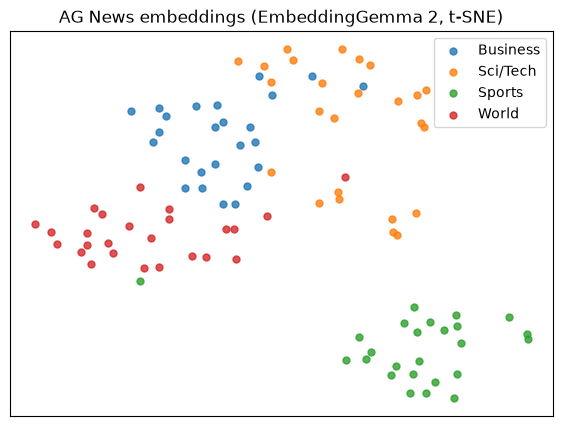

In [18]:
from sklearn.manifold import TSNE

labels = small_df["label"].to_numpy()

# Leave-one-out nearest-neighbor accuracy
sims = cosine_similarity(results)
np.fill_diagonal(sims, -np.inf)
nn_accuracy = (labels[sims.argmax(axis=1)] == labels).mean()
print(f"Nearest neighbor is from the same category in {nn_accuracy:.0%} of the news items (random: ~25%)")

# 2D map
points = TSNE(n_components=2, perplexity=15, init="pca", random_state=42).fit_transform(results)
fig, ax = plt.subplots(figsize=(7, 5))
for category in sorted(set(labels)):
    mask = labels == category
    ax.scatter(points[mask, 0], points[mask, 1], label=category, s=25, alpha=0.8)
ax.legend()
ax.set_title("AG News embeddings (EmbeddingGemma 2, t-SNE)")
ax.set_xticks([])
ax.set_yticks([])
plt.show()

The map shows a clear structure: **Sports** forms its own island, **World** is mostly separate, and **Business** and **Sci/Tech** sit next to each other with some overlap, which is expected, since technology companies, markets, and corporate news share a lot of vocabulary. For 85% of the news items, the nearest neighbor belongs to the same category, against ~25% by chance.

## 🌐 Multimodal embeddings

So far, we've only been working with text. But **EmbeddingGemma 2** is a multimodal embedding model: it maps text, images, video, and audio into the same vector space. (PDFs are not on that list; we'll get back to them.)

All the images, audios, videos, and PDFs we'll use are in this notebook's repository (folders `images/`, `audios/`, `videos/`, and `PDFs/`). If you cloned the repository, they're read straight from disk; otherwise (in Colab, for example) they're downloaded from GitHub. Either way, each file is loaded only once (`functools.cache`). For display, we shrink images to small JPEG thumbnails: the PNGs are 5–11 MB each, and we don't want them inside the notebook.

In [19]:
# Where to download the files from when they aren't on disk (if you fork or rename the repository, update this)
BASE_URL = "https://raw.githubusercontent.com/fabriciocarraro/EmbeddingGemma-2-Complete-Guide/main"

@functools.cache
def load_file(path: str) -> bytes:
    """Read a file of the repository from disk if it's there, otherwise download it from GitHub."""
    if os.path.exists(path):
        with open(path, "rb") as f:
            return f.read()
    response = requests.get(f"{BASE_URL}/{path}", timeout=60)
    response.raise_for_status()
    return response.content

print("Files: read from disk" if os.path.isdir("images") else f"Files: downloaded from {BASE_URL}")

def to_pil(data) -> Image.Image:
    """Bytes (or a PIL image) → RGB PIL image, which is what the model receives."""
    image = data if isinstance(data, Image.Image) else Image.open(io.BytesIO(data))
    return image.convert("RGB")

def thumbnail(data, size=300) -> str:
    """Small JPEG data URI, only for displaying images in the notebook."""
    image = to_pil(data).copy()
    image.thumbnail((size, size))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=85)
    return "data:image/jpeg;base64," + base64.b64encode(buffer.getvalue()).decode()

def show_ranking(items, size=150):
    """Display (image, score) pairs side by side, with the score on top."""
    html = '<div style="display:flex; gap:10px; text-align:center;">'
    for image, score in items:
        html += f'<div><div style="font-weight:bold; margin-bottom:5px;">{score:.4f}</div><img src="{thumbnail(image)}" width="{size}"></div>'
    display(HTML(html + "</div>"))

Files: read from disk


### 🖼️ Handling images

This means we can embed an image and compare it directly against our text vocabulary using cosine similarity, just like before.

#### Image & text

Let's test this: we'll load an image, embed it, and see which words from our vocabulary are closest to it. If the model works well, the top results should describe what's in the image. Since the goal is to match an image to our word vocabulary, no source words should be removed.

One adaptation: in a cross-modal comparison, the **text side** is what gets the prompt (the image is passed as it is). We use the `SearchQuery` prompt for the words, following the model card's rule for text-to-media retrieval, so we embed the vocabulary once more with that prompt.


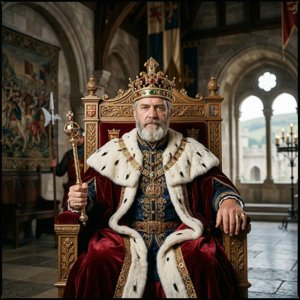

In [20]:
king_image_bytes = load_file("images/image_1.png")

display(HTML(f'<img src="{thumbnail(king_image_bytes)}" width="300">'))

To create its embedding, there's no special "Part" object like in the Gemini SDK: we just hand the model a PIL image (a file path or URL would also work).

Also, let's see what are the 10 words that match the embedding of this image the most.

In [21]:
# Getting the embedding for the king image (images take no prompt)
king_image_embedding = get_embedding(to_pil(king_image_bytes))

# The text side of a cross-modal comparison uses the query prompt
my_vocabulary_query_embeddings = get_embedding(my_vocabulary_words, prompt_name="SearchQuery")

# Comparing the king image embedding against all words in our vocabulary
scores_king_img = []
for label, emb in zip(my_vocabulary_words, my_vocabulary_query_embeddings):
    scores_king_img.append((label, cosine_similarity([king_image_embedding], [emb])[0, 0]))

scores_king_img = sorted(scores_king_img, key=lambda x: x[1], reverse=True)

df_king_img = pd.DataFrame(scores_king_img[:10], columns=["Word", "Cosine Similarity"])
df_king_img.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Word,Cosine Similarity
king,0.734923
queen,0.668909
capital,0.646980
CEO,0.645876
chair,0.645216
Rome,0.615900
Italy,0.614047
computer,0.613940
thunder,0.610158
USA,0.609706


The word "king" correctly comes on top (0.73), followed by "queen" (0.67), which makes sense for a royal portrait. The scores are lower than in the word-to-word experiments (comparing an image with a word is a harder task), but the ranking is spot on.

#### Image & image

So far we've been working a lot with text, but we can also use images as our "vocabulary" instead of words.


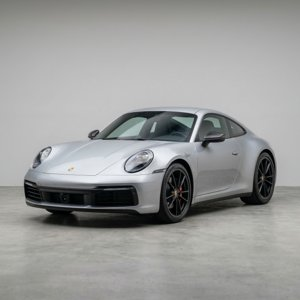
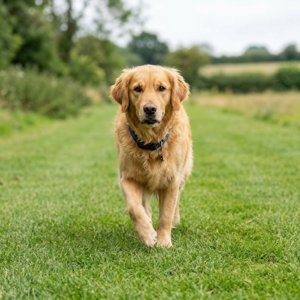
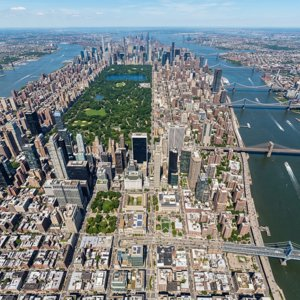
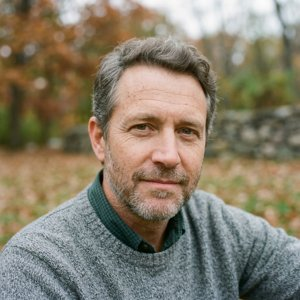
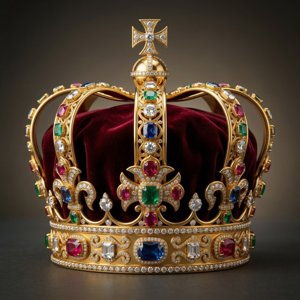
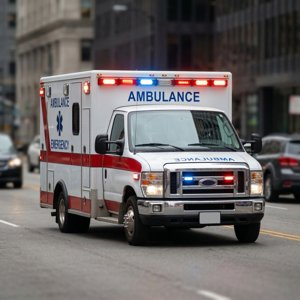

In [22]:
# Our image vocabulary: 6 images covering different categories
my_vocabulary_images = {
    "car": "images/image_2.png",
    "dog": "images/image_3.png",
    "city": "images/image_4.png",
    "man": "images/image_5.png",
    "crown": "images/image_6.png",
    "ambulance": "images/image_7.png",
}

# Download all images and store their raw bytes (reused for both embedding and display)
my_vocabulary_images_bytes = [load_file(path) for path in my_vocabulary_images.values()]

# Display the 6 images side by side
html = ""
for im_bytes in my_vocabulary_images_bytes:
    html += f'<img src="{thumbnail(im_bytes)}" width="150" style="margin:5px">'
display(HTML(html))

Let's compare the embedding of the king's image to the six images above. Which one will be the most similar?

crown (0.81) > man (0.68) > dog (0.64) > city (0.63) > ambulance (0.61) > car (0.56)



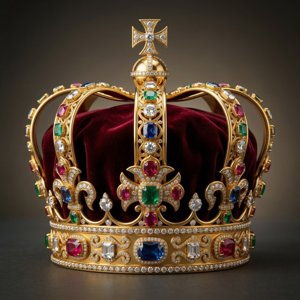
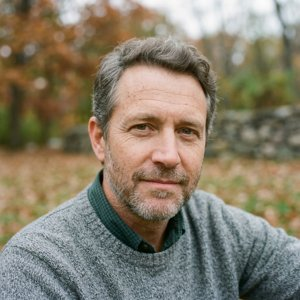
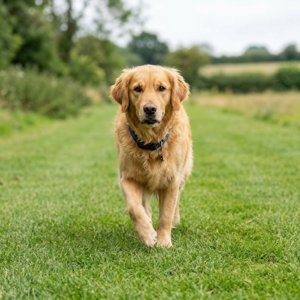
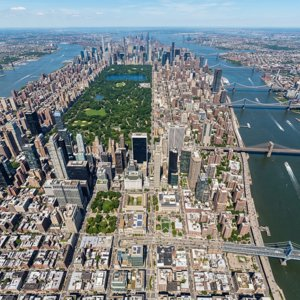
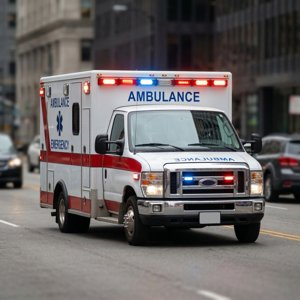
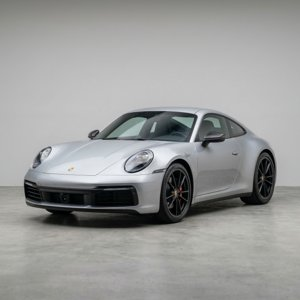

In [23]:
# Embed the 6 images in one batch
my_vocabulary_images_embeddings = get_embedding([to_pil(b) for b in my_vocabulary_images_bytes])

# Compare each image's embedding against the king image
scores_king_vs_images = []
for name, img_bts, emb in zip(my_vocabulary_images, my_vocabulary_images_bytes, my_vocabulary_images_embeddings):
    scores_king_vs_images.append((name, img_bts, cosine_similarity([king_image_embedding], [emb])[0, 0]))

scores_king_vs_images = sorted(scores_king_vs_images, key=lambda x: x[2], reverse=True)
print(" > ".join(f"{name} ({score:.2f})" for name, _, score in scores_king_vs_images))

# Display all 6 images ranked by similarity, with scores on top
show_ranking([(img_bts, score) for _, img_bts, score in scores_king_vs_images])

The crown comes out on top with 0.81, which makes sense, since it's the most visually and semantically connected to a king. The man comes second, and the car comes last.

#### Experimenting with multimodal embeddings

We can even apply the same arithmetic tricks we used with single words. If we take the king image embedding and subtract the crown image embedding, what image is closest to the result?

man (0.12) > dog (0.01) > city (-0.00) > ambulance (-0.03) > car (-0.07)



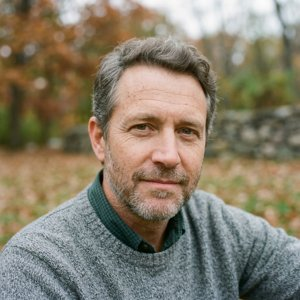
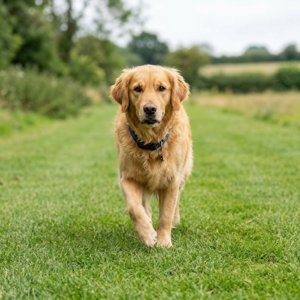
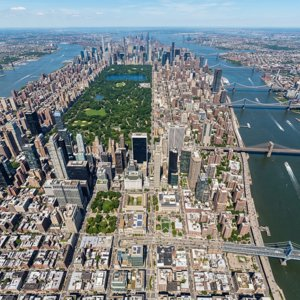
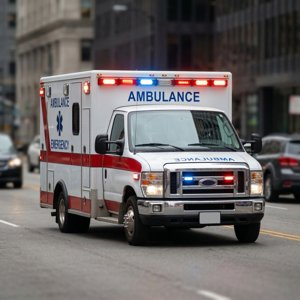
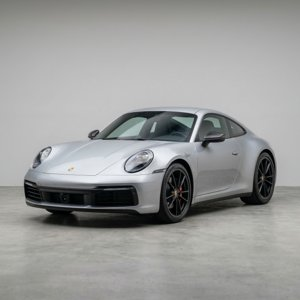

In [24]:
# Creating the embedding of the crown's image
crown_image_embedding = get_embedding(to_pil(load_file("images/image_6.png")))

# Performing an arithmetic operation with embeddings: king - crown
operation3_embedding = king_image_embedding - crown_image_embedding

# Removing the crown from the comparison
scores_op3 = []
for name, img_bts, emb in zip(my_vocabulary_images, my_vocabulary_images_bytes, my_vocabulary_images_embeddings):
    if name != "crown":
        scores_op3.append((name, img_bts, cosine_similarity([operation3_embedding], [emb])[0, 0]))
scores_op3 = sorted(scores_op3, key=lambda x: x[2], reverse=True)
print(" > ".join(f"{name} ({score:.2f})" for name, _, score in scores_op3))

# Display all 5 images ranked by similarity, with scores on top
show_ranking([(img_bts, score) for _, img_bts, score in scores_op3])

The image of the man comes out on top: you take a king, remove his crown, and you're left with a man. Cool!

Notice how small the scores are now (from −0.07 to 0.12): subtracting two similar vectors cancels most of what they share, and what's left is a small "difference" vector. Only the ranking matters here. And remember that this kind of operation is not what the model was trained for, so this trick may not always work perfectly.

#### Image search

**Image Similarity Search with EmbeddingGemma 2 and FAISS**

We will build an image similarity search engine using EmbeddingGemma 2 and [FAISS](https://github.com/facebookresearch/faiss). The idea is simple: we take a collection of images, convert each one into a dense vector (an embedding) that captures its visual semantics, and store those vectors in a searchable index. When a new query image comes in, we embed it the same way and find the closest vectors in the index — which correspond to the most visually similar images. We use the Tiny ImageNet dataset as our image collection and demonstrate the full pipeline from loading data, batching, building the index, and finally searching with your own uploaded image.

**Loading the Dataset**

We load the [Tiny ImageNet](https://huggingface.co/datasets/zh-plus/tiny-imagenet) dataset from Hugging Face, which contains small 64×64 images across 200 different classes. To build a meaningful search index, we want diversity — so instead of grabbing the first 100 images (which might all be the same class), we sample up to 5 images per label. This ensures our index covers as many different categories as possible.

In [25]:
ds = load_dataset("zh-plus/tiny-imagenet", split="train")

# Pick ~5 images per label to get diversity across labels
samples_per_label = defaultdict(list)
for item in ds:
    label = item["label"]
    if len(samples_per_label[label]) < 5:
        samples_per_label[label].append(item)
    if sum(len(v) for v in samples_per_label.values()) >= 100:
        break

samples = [item for items in samples_per_label.values() for item in items][:100]
print(f"Collected {len(samples)} images from {len(samples_per_label)} different labels")

Collected 100 images from 20 different labels


**Embedding Function**

The Gemini version needed a `pil_to_bytes` helper, because the API expects raw bytes. Here the model takes PIL images directly, so all we need is `get_image_embedding`, which receives a **list** of images and embeds them in batches on the GPU (`batch_size` images at a time). The result is a matrix with one embedding vector per image.

In [26]:
def get_image_embedding(images: list[Image.Image], batch_size: int = 16) -> np.ndarray:
    """Embed a list of PIL images with EmbeddingGemma 2."""
    return get_embedding([to_pil(img) for img in images], batch_size=batch_size)

**Embedding the Dataset**

We iterate over all 100 sampled images, collecting their metadata (label and original PIL image) for later display, and then embed all of them in a single call. Since everything is local, "batching" now means how many images go through the GPU at once, not how many API round trips we make.

In [27]:
print("Embedding 100 images...")
images = []
metadata = []  # store label + PIL image for display

for i, item in enumerate(samples):
    img: Image.Image = item["image"]  # already PIL from datasets lib
    label: int = item["label"]

    images.append(img)
    metadata.append({"label": label, "image": img, "index": i})

start = time.time()
embeddings = get_image_embedding(images)
print(f"Done in {time.time() - start:.1f}s")

Embedding 100 images...


Done in 19.4s


**Building the FAISS Index**

We stack all 100 embedding vectors into a matrix and build a FAISS index for fast similarity search. Before indexing, we L2-normalize each vector so that the inner product between any two vectors equals their cosine similarity — meaning the search ranks results purely by the angle between embeddings, ignoring magnitude. We use `IndexFlatIP` (flat inner product), which performs an exact brute-force search. With only 100 images this is perfectly fast; for larger datasets you'd swap this for an approximate index like `IndexIVFFlat` or `IndexHNSWFlat` to trade a little accuracy for much faster search.

In [28]:
embeddings_matrix = np.array(embeddings, dtype="float32")

faiss.normalize_L2(embeddings_matrix)

dim = embeddings_matrix.shape[1]
index = faiss.IndexFlatIP(dim)
index.add(embeddings_matrix)

print(f"\nFAISS index built: {index.ntotal} vectors of dimension {dim}")


FAISS index built: 100 vectors of dimension 768


**Search & Visualization**

`search_similar_images` takes any PIL image as a query, embeds it, normalizes it, and runs it against the FAISS index — returning the top-k most similar images along with their cosine scores. `show_results` then renders the query and its matches side by side using matplotlib, with each result annotated with its rank, label, and similarity score. The higher the score (max 1.0), the closer the query and result are in the embedding space.

In [29]:
def search_similar_images(query_image: Image.Image, top_k: int = 5):
    """Given a query PIL image, return the top-k most similar images."""
    query_vec = get_image_embedding([query_image])

    faiss.normalize_L2(query_vec)

    scores, indices = index.search(query_vec, top_k)

    print(f"\nTop {top_k} most similar images:")
    results = []
    for rank, (idx, score) in enumerate(zip(indices[0], scores[0])):
        meta = metadata[idx]
        print(f"  Rank {rank+1} | Index: {idx} | Label: {meta['label']} | Score: {score:.4f}")
        results.append({"rank": rank + 1, "score": score, **meta})

    return results

def show_results(query: Image.Image, results: list[dict], query_label=None):
    fig, axes = plt.subplots(1, len(results) + 1, figsize=(15, 3))

    axes[0].imshow(query)
    axes[0].set_title("Query" + (f"\nLabel: {query_label}" if query_label is not None else ""), fontsize=9)
    axes[0].axis("off")

    for ax, res in zip(axes[1:], results):
        ax.imshow(res["image"])
        ax.set_title(f"Rank {res['rank']}\nLabel: {res['label']}\nScore: {res['score']:.3f}", fontsize=8)
        ax.axis("off")

    plt.suptitle("EmbeddingGemma 2 + FAISS Image Search", fontweight="bold", y=1.05)
    plt.tight_layout()
    plt.savefig("similarity_results.png", dpi=150, bbox_inches="tight")
    plt.show()

**Search with Your Own Image**

Upload any image from your machine and run it as a query against the index. In Colab, `files.upload()` opens a file picker (the notebook waits here until you pick a file or click "Cancel upload"); locally, set `MY_IMAGE_PATH` to an image on your disk. If you do neither (or the notebook runs headless), we use an image from Tiny ImageNet's **validation** split, which is **not** in the index, so we can check whether the results come from the same class. Keep in mind that since the index only contains 100 images, results will be limited — the more images you index, the better the search quality.


Top 5 most similar images:
  Rank 1 | Index: 3 | Label: 0 | Score: 0.8992
  Rank 2 | Index: 4 | Label: 0 | Score: 0.8742
  Rank 3 | Index: 2 | Label: 0 | Score: 0.8720
  Rank 4 | Index: 1 | Label: 0 | Score: 0.8605
  Rank 5 | Index: 0 | Label: 0 | Score: 0.8497


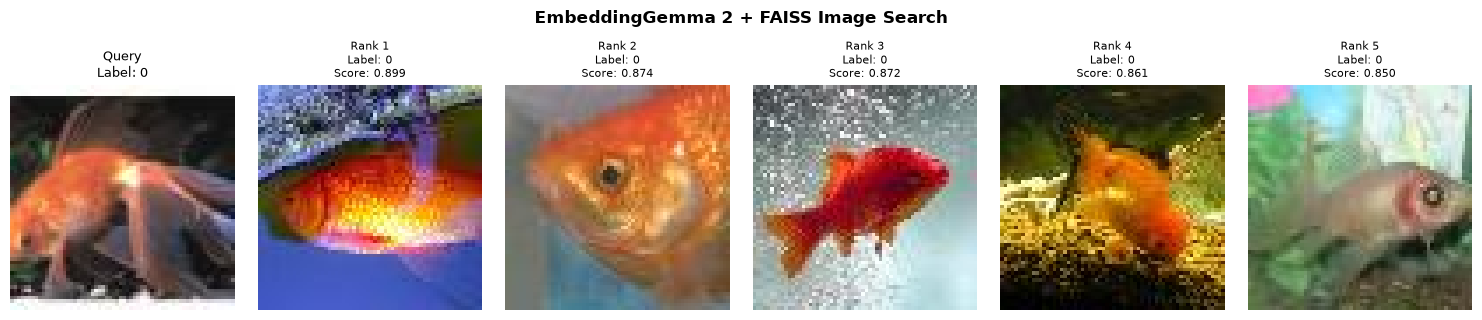

In [30]:
MY_IMAGE_PATH = None  # e.g. "my_photo.jpg"
my_image, my_image_label = None, None

if MY_IMAGE_PATH:
    my_image = Image.open(MY_IMAGE_PATH)
elif IN_COLAB and not HEADLESS:
    from google.colab import files
    uploaded = files.upload()  # Opens a file picker in the notebook ("Cancel upload" uses the fallback below)
    if uploaded:
        filename = list(uploaded.keys())[0]
        my_image = Image.open(io.BytesIO(uploaded[filename]))

if my_image is None:
    # Fallback: the first validation image whose class is in our index
    validation = load_dataset("zh-plus/tiny-imagenet", split="valid")
    query_item = next(item for item in validation if item["label"] in samples_per_label)
    my_image, my_image_label = query_item["image"], query_item["label"]

results = search_similar_images(my_image, top_k=5)
show_results(my_image, results, query_label=my_image_label)

Since nothing was uploaded in this run, the query was a goldfish (label 0) from the validation split, which is **not** in the index. All 5 results are goldfish too: they are exactly the 5 goldfish images in our 100-image index, with scores between 0.85 and 0.90. Not bad for 64×64-pixel images!

### 🧩 Combined embeddings

Another great thing about this model is that it allows us to create a single combined embedding aggregating more than one modality in the same input. For example, for a social media post with one or more images, we can aggregate the text and the image(s) into one embedding to create a coherent post-level representation.

With Gemini, that was done with `types.Content(parts=[...])`. With EmbeddingGemma 2 and `sentence-transformers`, we pass **a dict**: the text goes under `"text"` and the media under `"image"` (or `"audio"`, `"video"`). Inside the text, the placeholder `<|image|>` marks *where* each image goes, and the call returns **one** embedding for the whole thing. Everything shares the same 8,192-token budget (each image costs 280 tokens by default).

Prompts: this is a retrieval task (a query looking for posts), so the posts get the `Document` prompt and the query gets `SearchQuery`. The prompt is only added to the text part of a dict.

Let's begin creating some social media posts (the exact same ones as in the original guide):
  - Post 1: Text-only about Gemini Embedding 2
  - Post 2: Image-only carousel about Gemini Embedding 2
  - Post 3: Text + image post about the Gemini zodiac sign
  - Post 4: Text + image post about the Gemini mission from NASA
  - Post 5: Text-only tweet about cooking

In [31]:
# Post 1: Text-only about Gemini Embedding 2
post1_text = """
    Google just dropped a game-changer for AI developers. Gemini Embedding 2 is officially here, and it’s not just a "text upgrade"—it is Google’s first natively multimodal embedding model.

    For years, building multimodal search (like searching video via text) meant stitching together different models—one for images, one for audio, and another for text. Gemini Embedding 2 collapses that complexity into a single, unified vector space.

    Why this matters for your AI stack:
    One Vector Space to Rule Them All: You can now map text, images, audio, video, and PDFs into the same embedding space. This means you can query a video library using a text prompt or find similar audio clips using an image—no intermediate transcription required.

    Massive Context Jump: The text context window has quadrupled to 8,192 tokens. You can now embed much larger "chunks" of data, preserving the nuance and relationship in complex documents.

    Native Audio Intelligence: It skips the "Speech-to-Text" middleman. By embedding audio natively, the model captures acoustic intent and "soul" that transcriptions often lose.

    Efficiency by Design: Using Matryoshka Representation Learning (MRL), you can scale your embeddings from 3,072 dimensions down to 768 without a total collapse in accuracy. High quality, lower storage costs.

    Performance Benchmarks 📈
    In recent tests, Gemini Embedding 2 is outperforming industry peers (like Amazon Nova 2 and Voyage 3.5), particularly in text-to-video and cross-modal reasoning tasks.

    The catch? Because the geometric mapping is entirely new, you’ll need to re-index your old vectors to take advantage of this unified space. But for the ability to search across 100+ languages and 5 different media types in one call? It’s a no-brainer.

    Available now in public preview via Gemini API and Vertex AI.

    Time to build smarter, simpler RAG pipelines. 🛠️
    """

post1_embedding = get_embedding(post1_text, prompt_name="Document")

post1 = {
    "title": "Post 1: Text-only about Gemini Embedding 2",
    "embedding": post1_embedding
}


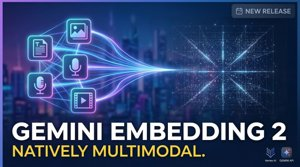
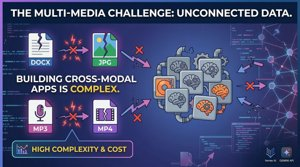
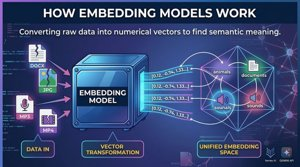
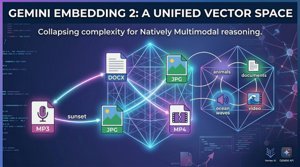
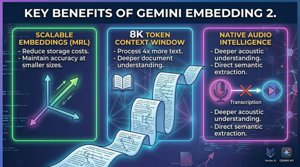
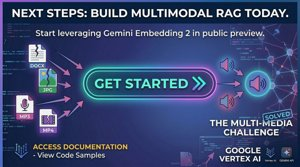

6 images → one embedding of shape (768,)


In [32]:
# Post 2: Image-only carousel about Gemini Embedding 2
post2_images = [
    "images/image_8.png",
    "images/image_9.png",
    "images/image_10.png",
    "images/image_11.png",
    "images/image_12.png",
    "images/image_13.png",
]

post2_images_bytes = [load_file(path) for path in post2_images]

# showing the 6 images side by side
html = ""
for im_bytes in post2_images_bytes:
    html += f'<img src="{thumbnail(im_bytes)}" width="200" style="margin:5px">'
display(HTML(html))

# generating ONE combined embedding for the 6 images: a list under the "image" key
post2_combined_embedding = get_embedding({"image": [to_pil(b) for b in post2_images_bytes]})

post2 = {
    "title": "Post 2: Image-only carrousel about Gemini Embedding 2",
    "embedding": post2_combined_embedding
}
print(f"6 images → one embedding of shape {post2_combined_embedding.shape}")


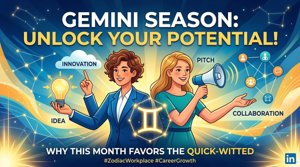

In [33]:
# Post 3: Text + image post about the Gemini zodiac sign
post3_text = """
    Gemini Season is Approaching: Time to Double the Energy!
    As we move into the season of the Twins, it’s time to celebrate the most versatile, intellectually curious, and—let’s be honest—vibrant sign of the zodiac.

    If you have Geminis on your team (or if you’re lucky enough to be one), get ready. This month isn't just about birthdays; it’s about a massive shift in creative momentum and collaborative breakthroughs.

    Why Geminis are Owning the Month:
    The Ultimate Networkers: Expect your LinkedIn feed to buzz. Geminis thrive on connection, and this month, their ability to bridge gaps between ideas and people is at an all-time high.

    Adaptive Intelligence: While others might see change as a hurdle, Geminis see it as a playground. This month favors those who can pivot quickly—a Gemini superpower.

    Communication Mastery: Whether it’s a high-stakes pitch or a team brainstorm, the "Gift of Gab" is evolving into the "Gift of Strategy."

    The Forecast: High Energy & High Impact
    The celestial alignment suggests a month of "unlocked potential." For the Geminis in the room, the mental fog is clearing, making way for sharp decision-making and fresh perspectives. It’s a period for starting those "bold idea" projects that have been sitting on the back burner.

    Pro-Tip: If you're working with a Gemini this month, lean into their agility. They are the catalysts that turn a stagnant meeting into a masterclass in innovation.

    Happy (almost) birthday to the quick-witted, the multi-faceted, and the forever-curious! Let’s make this season one for the books. 🚀"""

# displaying post image
post3_image_bytes = load_file("images/image_14.png")
display(HTML(f'<img src="{thumbnail(post3_image_bytes)}" width="300">'))

# generating combined embeddings text + image: <|image|> marks where the image goes
post3_combined_embedding = get_embedding(
    {"text": post3_text + "\n<|image|>", "image": to_pil(post3_image_bytes)},
    prompt_name="Document",
)

post3 = {
    "title": "Post 3: Text + image post about the Gemini zodiac sign",
    "embedding": post3_combined_embedding
}


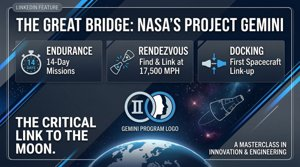

In [34]:
# Post 4: Text + image post about the Gemini mission from NASA
post4_text = """
    The "Great Bridge": Remembering NASA’s Project Gemini 🚀
    While the Apollo missions took the giant leap, Project Gemini was the essential bridge that got us there. Often tucked between the pioneering Mercury flights and the historic Moon landings, Gemini was where NASA truly learned how to fly in space.

    Launched in the mid-1960s, Gemini wasn't just about going up; it was about mastering the "how-to" of space exploration. Here is why this underrated program changed everything:

    The Mission Milestones
    Gemini proved that the ambitious goals of Apollo were actually possible by hitting three critical benchmarks:

    Endurance: Can humans survive in space for two weeks? Gemini 7 proved we could, lasting 14 days in a cockpit the size of a front seat of a car.

    Rendezvous and Docking: To get to the Moon, we had to learn how to find and link two spacecraft moving at 17,500 mph. Gemini 6 and 7 achieved the first rendezvous; Gemini 8 achieved the first docking.

    EVAs (Space Walks): Ed White became the first American to step out into the void during Gemini 4, proving humans could work outside the craft.

    The Legacy of Innovation
    The program wasn't just about hardware; it was a masterclass in iterative engineering and risk management. It featured the first use of fuel cells in a manned spacecraft and the first onboard computer to assist with maneuvers.

    Today, as we look toward the Artemis missions and Mars, we owe a debt to the ten crews who pushed the boundaries of what was "impossible" in low Earth orbit.

    "Gemini was the most important program of all... It was the bridge to the Moon."
    — Neil Armstrong, Gemini 8 and Apollo 11 Astronaut"""

# displaying post image
post4_image_bytes = load_file("images/image_15.png")
display(HTML(f'<img src="{thumbnail(post4_image_bytes)}" width="300">'))

# generating combined embeddings text + image
post4_combined_embedding = get_embedding(
    {"text": post4_text + "\n<|image|>", "image": to_pil(post4_image_bytes)},
    prompt_name="Document",
)

post4 = {
    "title": "Post 4: Text + image post about the Gemini mission from NASA",
    "embedding": post4_combined_embedding
}

In [35]:
# Post 5: Text-only tweet about cooking
post5_text = """Cooking is one part science, two parts intuition, and ten parts "hopefully I didn't just ruin this pan." 🍳
Whether you're mastering a 30-minute weekday meal or finally tackling that 12-hour brisket, there’s nothing quite like the kitchen becoming the heart of the home."""

post5_embedding = get_embedding(post5_text, prompt_name="Document")

post5 = {
    "title": "Post 5: Text-only tweet about cooking",
    "embedding": post5_embedding
}

Now that we have our 5 posts, let's generate a text-only tweet about the Gemini 3 AI model as our query and compare its embedding with the 5 above:

In [36]:
# Our query:
query_text = """Just dropped my first project using Gemini 3.1 Pro and the agentic coding capabilities are next level. 💻
    Achieving a 77.1% on ARC-AGI-2? That reasoning jump is wild. If you haven't tried the new "Deep Think" mode in AI Studio yet, you're missing out."""

query_embedding = get_embedding(query_text, prompt_name="SearchQuery")

In [37]:
# Creating a list with the 5 posts
post_list = [post1, post2, post3, post4, post5]

scores_combined = []
for post in post_list:
    score = cosine_similarity([query_embedding], [post["embedding"]])[0, 0]
    scores_combined.append((post["title"], score))

scores_combined = sorted(scores_combined, key=lambda x: x[1], reverse=True)

print("\nMost similar posts to our query:\n")
df_posts = pd.DataFrame(scores_combined, columns=["Post", "Cosine Similarity"])
df_posts.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])


Most similar posts to our query:



Post,Cosine Similarity
Post 2: Image-only carrousel about Gemini Embedding 2,0.673974
Post 4: Text + image post about the Gemini mission from NASA,0.656830
Post 1: Text-only about Gemini Embedding 2,0.631654
Post 3: Text + image post about the Gemini zodiac sign,0.622424
Post 5: Text-only tweet about cooking,0.608367


Both posts about the Gemini AI model are in the top three, and **the image-only carousel (Post 2) wins** (0.67), followed by the NASA post (0.66) and the text-only post about Gemini Embedding 2 (0.63); the zodiac post and the cooking tweet come last.

Two observations:
- The winner makes sense: the carousel *is* about an AI model called Gemini, which is what the query talks about. The model connected a text query to a set of slides, with no text in that input at all.
- The spread is small (all five posts are between 0.61 and 0.67), and the NASA post sneaking into second place shows that the word "Gemini" alone still pulls a bit.

And there's a twist: **the prompt changes the answer**. Let's run the exact same comparison, but treating it as a symmetric "how similar are these two texts?" task, with `SentenceSimilarity` for everyone:

In [38]:
# Same posts, same query, but now as a symmetric "how similar are these two texts?" task
query_embedding_sym = get_embedding(query_text, prompt_name="SentenceSimilarity")
posts_sym = {
    post1["title"]: get_embedding(post1_text, prompt_name="SentenceSimilarity"),
    post2["title"]: post2_combined_embedding,  # images only: there's no text to put a prompt on
    post3["title"]: get_embedding({"text": post3_text + "\n<|image|>", "image": to_pil(post3_image_bytes)}, prompt_name="SentenceSimilarity"),
    post4["title"]: get_embedding({"text": post4_text + "\n<|image|>", "image": to_pil(post4_image_bytes)}, prompt_name="SentenceSimilarity"),
    post5["title"]: get_embedding(post5_text, prompt_name="SentenceSimilarity"),
}

scores_combined_sym = sorted(
    [(title, cosine_similarity([query_embedding_sym], [emb])[0, 0]) for title, emb in posts_sym.items()],
    key=lambda x: x[1],
    reverse=True,
)

df_posts_sym = pd.DataFrame(scores_combined_sym, columns=["Post (SentenceSimilarity prompt)", "Cosine Similarity"])
df_posts_sym.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Post (SentenceSimilarity prompt),Cosine Similarity
Post 1: Text-only about Gemini Embedding 2,0.787688
Post 5: Text-only tweet about cooking,0.780585
Post 4: Text + image post about the Gemini mission from NASA,0.754231
Post 3: Text + image post about the Gemini zodiac sign,0.740642
Post 2: Image-only carrousel about Gemini Embedding 2,0.718985


Now the text-only Post 1 wins (0.79), but look at second place: the cooking tweet (0.78), ahead of every other Gemini post! With the similarity prompt, the model pays a lot of attention to *how* the text is written: our query is a short, casual, emoji-filled tweet, and so is the cooking post. With the search prompt, the topic weighs more and the writing style less. The image-only carousel drops to last place.

This is what "task-steered representations" means in practice: the same content gets a different vector depending on the task you declare, so pick the prompt for the question you're actually asking. (Fun fact: this second ranking is exactly the one Gemini Embedding 2 produced for these posts, without any prompt.)

### 🔊 Handling audio

#### Audio & text

EmbeddingGemma 2 also handles audio natively: there's an audio encoder inside the model that listens to the raw waveform, so there is no speech-to-text step. The difference from Gemini is in *how* we hand it the audio: the model expects a **mono waveform sampled at 16 kHz**. Our MP3s are stereo, at 24 kHz or 44.1 kHz, so we decode and resample them first with `librosa`. (Passing a local file path or URL to `encode()` also works, and `sentence-transformers` decodes it for you; doing it explicitly just makes the requirement visible.)

Audio costs 25 tokens per second, so a single input can hold up to ~5 minutes of sound. Let's search our 4 audio files using a text query:

In [39]:
def load_audio_16k(audio_bytes: bytes) -> dict:
    """Decode an audio file to a 16 kHz mono waveform, the format EmbeddingGemma 2 expects."""
    waveform, sampling_rate = librosa.load(io.BytesIO(audio_bytes), sr=16000, mono=True)
    return {"array": waveform, "sampling_rate": sampling_rate}

In [40]:
# 4 audio files covering different sound categories
audio_files = {
    "audio_01 - ambulance": "audios/audio_01.mp3",
    "audio_02 - rain": "audios/audio_02.mp3",
    "audio_03 - birds": "audios/audio_03.mp3",
    "audio_04 - wolf": "audios/audio_04.mp3",
}

# Download, decode and embed each audio file (no transcription needed)
audio_embeddings = {}

for filename, path in audio_files.items():
    audio = load_audio_16k(load_file(path))
    audio_embeddings[filename] = get_embedding(audio)
    print(f"{filename}: {len(audio['array']) / 16000:.1f}s")

print(f"{len(audio_embeddings)} audio files embedded!")

audio_01 - ambulance: 15.5s


audio_02 - rain: 22.1s
audio_03 - birds: 19.2s


audio_04 - wolf: 8.1s
4 audio files embedded!


In [41]:
# Our text query (notice it never says "ambulance")
query_text = "Emergency vehicle siren"
query_emb = get_embedding(query_text, prompt_name="SearchQuery")

# Compare our text query against all audio embeddings
scores_audio = []
for filename, emb in audio_embeddings.items():
    score = cosine_similarity([query_emb], [emb])[0, 0]
    scores_audio.append((filename, score))

scores_audio = sorted(scores_audio, key=lambda x: x[1], reverse=True)

print(f'Query: "{query_text}"\n')
df_audios1 = pd.DataFrame(scores_audio, columns=["Audio file", "Cosine Similarity"])
df_audios1.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Query: "Emergency vehicle siren"



Audio file,Cosine Similarity
audio_01 - ambulance,0.662296
audio_04 - wolf,0.634665
audio_02 - rain,0.625392
audio_03 - birds,0.595079


And the ambulance siren comes out on top (0.66), with a clear gap to the wolf howl (0.63), even though the query never says "ambulance".

Query wording matters here: with the question "What sound is associated with an emergency vehicle?", the wolf and the ambulance came out practically tied (0.685 vs 0.682). When a result surprises you, try rephrasing the query before blaming the model.

#### Audio & audio

Now let's try audio-to-audio search. We recorded a short voice clip describing a scary experience in the forest at night, but without ever mentioning howling, wolves, or even the word "animal". Let's embed it and see which of our 4 audio files the model considers most similar:

In [42]:
# Download and play our voice clip
audio_vs_audio_bytes = load_file("audios/audio_06.mp3")

Audio(data=audio_vs_audio_bytes, autoplay=False)

In [43]:
# Create the embedding for the voice clip
audio_vs_audio_emb = get_embedding(load_audio_16k(audio_vs_audio_bytes))

# Compare the embedding of our voice clip against all audio embeddings
scores_audio_vs_audio = []
for filename, emb in audio_embeddings.items():
    score = cosine_similarity([audio_vs_audio_emb], [emb])[0, 0]
    scores_audio_vs_audio.append((filename, score))

scores_audio_vs_audio = sorted(scores_audio_vs_audio, key=lambda x: x[1], reverse=True)

print("Most similar audio file to our voice clip:\n")
df_audios2 = pd.DataFrame(scores_audio_vs_audio, columns=["Audio file", "Cosine Similarity"])
df_audios2.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Most similar audio file to our voice clip:



Audio file,Cosine Similarity
audio_04 - wolf,0.725978
audio_02 - rain,0.673974
audio_01 - ambulance,0.673905
audio_03 - birds,0.657194


The wolf howl ranks first (0.73) with a clear margin over the rest (0.66–0.67), even though the voice clip never says "wolf" or "howling". The model is comparing speech with environmental sound, two very different kinds of audio, and still seems to connect the meaning of the story (fear, a forest at night) with the right sound.

#### Audio & image

Since everything lives in the same embedding space, we can do something even more interesting: use an image to search for audio. Remember the ambulance image we used before? Let's take its embedding and see which audio file is closest to it:


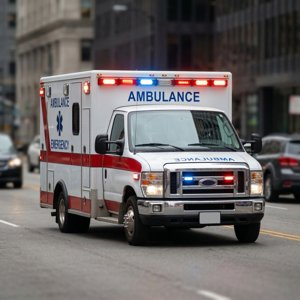

In [44]:
# Cross-modal search: using an image to find the most similar audio
ambulance_bytes = load_file("images/image_7.png")
ambulance_embedding = get_embedding(to_pil(ambulance_bytes))

html = f'<img src="{thumbnail(ambulance_bytes)}" width="150" style="margin:5px">'
display(HTML(html))

In [45]:
# Compare the ambulance image embedding against all audio embeddings
scores_img_vs_audio = []
for filename, emb in audio_embeddings.items():
    score = cosine_similarity([ambulance_embedding], [emb])[0, 0]
    scores_img_vs_audio.append((filename, score))

scores_img_vs_audio = sorted(scores_img_vs_audio, key=lambda x: x[1], reverse=True)

print("Most similar audio file to the ambulance image:\n")
df_audios3 = pd.DataFrame(scores_img_vs_audio, columns=["Audio file", "Cosine Similarity"])
df_audios3.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Most similar audio file to the ambulance image:



Audio file,Cosine Similarity
audio_02 - rain,0.616073
audio_01 - ambulance,0.576155
audio_04 - wolf,0.573721
audio_03 - birds,0.551221


This one doesn't work: the **rain** wins (0.62), and the ambulance siren comes second (0.58), practically tied with the wolf. We tried giving the image more detail (560 and 1,120 tokens instead of 280) and asking a question together with the image ("What sound does this make?"); neither put the siren on top. Let's look at why:

In [46]:
# Which of our 4 sounds is the closest to each of the 6 vocabulary images?
for name, image_emb in zip(my_vocabulary_images, my_vocabulary_images_embeddings):
    sims = {filename.split(" - ")[1]: cosine_similarity([image_emb], [emb])[0, 0] for filename, emb in audio_embeddings.items()}
    closest = max(sims, key=sims.get)
    print(f"{name:>10} image → {closest:<9} sound ({sims[closest]:.3f})")

       car image → rain      sound (0.596)
       dog image → rain      sound (0.627)
      city image → rain      sound (0.645)
       man image → birds     sound (0.657)
     crown image → rain      sound (0.609)
 ambulance image → rain      sound (0.616)


The rain is the closest sound to **5 of our 6 images**, whatever is in them. This is a well-known effect in embedding search called **hubness**: some items end up close to *everything*, and they win every query that has no strong match. Here, our rain clip behaves like one of those hubs for images.

In other words, in our tests, photo → sound effect was the weakest pairing of EmbeddingGemma 2, while the other audio experiments in this notebook (with speech or text on one side) worked. If you build a photo-to-sound search, test it on your own data and look into hubness-reduction techniques, such as subtracting each candidate's average similarity to a set of typical queries.

### 🎬 Handling video

EmbeddingGemma 2 embeds a video as a **sequence of frames** that go through its vision encoder. By default, the processor samples **1 frame per second**, keeps **at most 32 frames** (longer videos are re-sampled uniformly to 32), and spends **140 tokens per frame**, so a clip uses at most 32 × 140 = 4,480 of the 8,192 tokens. Just like with Gemini Embedding 2, **the audio track is not used**: if the sound matters, embed it separately as audio (or put both in one dict, `{"video": ..., "audio": ...}`).

**We raise the budget to 280 tokens per frame.** The vision budget is configurable (70, 140, 280, 560 or 1,120 tokens per image or frame), and the model card notes that more tokens capture finer visual detail. The default of 140 is a good fit for phones; on a laptop or Colab GPU we can afford more. Our clips are 9–16 seconds long (9 to 15 frames), so the longest one uses 15 × 280 = 4,200 tokens. For longer videos keep `frames × 280` under 8,192 (≈29 frames), or go back to 140.

**Why do we decode the frames ourselves?** You *can* pass a video file path or URL straight to `encode()`, but then `transformers` decodes it with `torchcodec`, which needs FFmpeg's shared libraries installed on your system. That tends to work on Linux, but often fails on Windows (it did on the machine this notebook was written on). So we use **PyAV** (whose wheels ship their own FFmpeg), pick exactly the frames the processor itself would pick (same 1 fps rule, same 32-frame cap), and tell the processor not to sample again with `do_sample_frames=False`. Same frames in, same embedding out, on any OS.

In [47]:
def load_video(video_bytes: bytes, fps: float = 1, max_frames: int = 32) -> dict:
    """Decode the frames EmbeddingGemma 2 would sample (fps-based, capped at max_frames) as PIL images."""
    with av.open(io.BytesIO(video_bytes)) as container:
        stream = container.streams.video[0]
        native_fps = float(stream.average_rate)
        duration = float(stream.duration * stream.time_base) if stream.duration else container.duration / av.time_base
        total_frames = stream.frames or round(duration * native_fps)

        # Same rule as the model's video processor: 1 frame every (native_fps / fps) frames...
        step = native_fps / fps
        indices = [min(total_frames - 1, int(i * step)) for i in range(max(1, int(duration * fps)))]
        # ...and, if there are too many, keep max_frames of them, uniformly spread
        if len(indices) > max_frames:
            indices = [indices[i] for i in np.linspace(0, len(indices) - 1, max_frames, dtype=int)]

        wanted = set(indices)
        frames = [frame.to_image() for i, frame in enumerate(container.decode(stream)) if i in wanted]

    metadata = {"fps": native_fps, "total_num_frames": total_frames, "duration": duration, "frames_indices": indices}
    return {"array": frames, "video_metadata": metadata}

# Our frames are already sampled, so the processor must not sample them again; 280 tokens per frame
VIDEO_KWARGS = {"video": {"do_sample_frames": False, "max_soft_tokens": 280}}

#### Video and text

The most straightforward approach: embed a text query and compare it against video embeddings to find the most semantically relevant clip. Let's first embed our 5 videos and take a look at the frames the model actually "sees":

5 videos embedded!




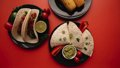
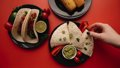
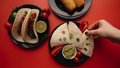
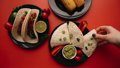
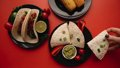
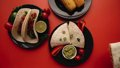
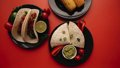
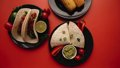
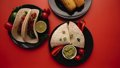
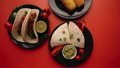
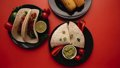
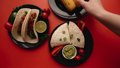
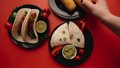
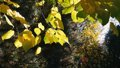
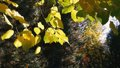
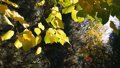
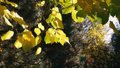
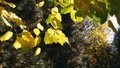
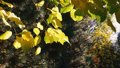
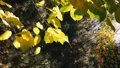
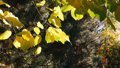
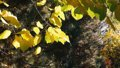
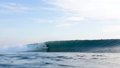
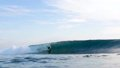
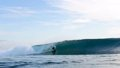
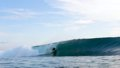
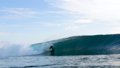
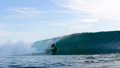
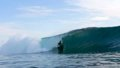
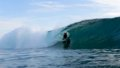
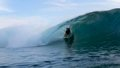
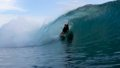
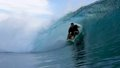
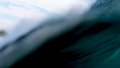
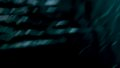
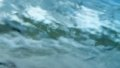
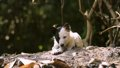
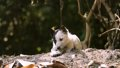
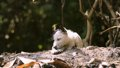
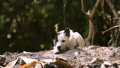
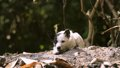
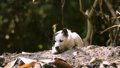
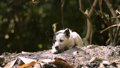
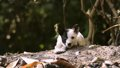
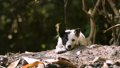
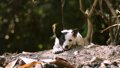
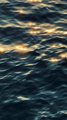
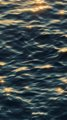
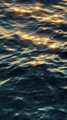
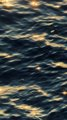
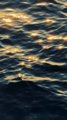
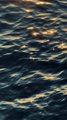
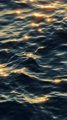
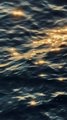
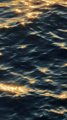
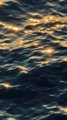
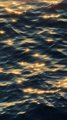
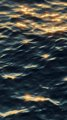
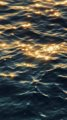
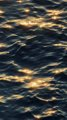
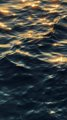

In [48]:
# 5 Videos covering very different topics:
video_files = {
    "Food": "videos/food.mp4",
    "Forest": "videos/forest.mp4",
    "Surf": "videos/surf.mp4",
    "Dog": "videos/dog.mp4",
    "Waves": "videos/waves.mp4",
}

# Download, decode and embed each video
videos = {}
video_embeddings = {}

for filename, path in video_files.items():
    videos[filename] = load_video(load_file(path))
    video_embeddings[filename] = get_embedding(videos[filename], processing_kwargs=VIDEO_KWARGS)

print(f"{len(video_embeddings)} videos embedded!\n")

# What the model sees: the sampled frames of each video
html = ""
for filename, video in videos.items():
    meta = video["video_metadata"]
    html += f"<b>{filename}</b>: {meta['duration']:.1f}s at {meta['fps']:.0f} fps → {len(video['array'])} frames<br>"
    html += "".join(f'<img src="{thumbnail(frame, 120)}" height="60" style="margin:1px">' for frame in video["array"])
    html += "<br>"
display(HTML(html))

In [49]:
# Our text query
query_text = "I'm searching for videos with animals to add in my documentary"
query_emb = get_embedding(query_text, prompt_name="SearchQuery")

# Compare the embedding of our text query against all video files
scores_video = []
for filename, emb in video_embeddings.items():
    score = cosine_similarity([query_emb], [emb])[0, 0]
    scores_video.append((filename, score))

scores_video = sorted(scores_video, key=lambda x: x[1], reverse=True)

print(f'\nQuery: "{query_text}"\n')
df_video1 = pd.DataFrame(scores_video, columns=["Video file", "Cosine Similarity"])
df_video1.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])


Query: "I'm searching for videos with animals to add in my documentary"



Video file,Cosine Similarity
Dog,0.652028
Waves,0.577653
Forest,0.555543
Surf,0.552272
Food,0.551646


The **Dog** video comes out on top (0.65), with a clear margin over the rest (Waves: 0.58). That's where the higher token budget pays off: with the default 140 tokens per frame, Dog and Waves came out practically tied (0.614 vs 0.620, with Waves ahead). With 280, the model sees each frame in more detail, and the animal video wins clearly.

#### Video and audio

In [50]:
# Download and play our voice clip
audio_video_bytes = load_file("audios/audio_05.mp3")

Audio(data=audio_video_bytes, autoplay=False)

In [51]:
# Create the embedding of our voice clip
audio_video_emb = get_embedding(load_audio_16k(audio_video_bytes))

# Compare the embedding of our voice clip against all video files
scores_video_vs_audio = []
for filename, emb in video_embeddings.items():
    score = cosine_similarity([audio_video_emb], [emb])[0, 0]
    scores_video_vs_audio.append((filename, score))

scores_video_vs_audio = sorted(scores_video_vs_audio, key=lambda x: x[1], reverse=True)

print("Most similar videos to our voice clip:\n")
df_video2 = pd.DataFrame(scores_video_vs_audio, columns=["Video file", "Cosine Similarity"])
df_video2.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Most similar videos to our voice clip:



Video file,Cosine Similarity
Dog,0.629259
Forest,0.572490
Waves,0.568491
Food,0.556546
Surf,0.526449


The voice clip about animals finds the **Dog** video first (0.63), well ahead of Forest and Waves (0.57). Audio → video, with no text in between.

#### Video and video

In [52]:
# Using the embedding of "Surf" as our query
surf_emb = video_embeddings["Surf"]

# Compare the embedding of "Surf" against all video files
scores_video_vs_video = []
for filename, emb in video_embeddings.items():
    if filename != "Surf": # removing itself from comparison
        score = cosine_similarity([surf_emb], [emb])[0, 0]
        scores_video_vs_video.append((filename, score))

scores_video_vs_video = sorted(scores_video_vs_video, key=lambda x: x[1], reverse=True)

print("Most similar videos to 'Surf':\n")
df_video3 = pd.DataFrame(scores_video_vs_video, columns=["Video file", "Cosine Similarity"])
df_video3.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Most similar videos to 'Surf':



Video file,Cosine Similarity
Waves,0.705641
Dog,0.633132
Forest,0.612006
Food,0.610348


Waves comes first (0.71): both are ocean videos. Dog comes second (0.63), and Forest and Food are practically tied for third (0.61).

### 📄 Handling PDF documents

Here is the biggest incompatibility. Gemini Embedding 2 embeds PDF files natively. **EmbeddingGemma 2 does not accept PDFs**: its inputs are text, images, audio, and video. There are two reasonable workarounds:

1. **Pages as images** (what we use below): render each page to an image and embed all the pages of a document together, in a single dict input, as one embedding. This is the closest thing to "native" PDF embedding, because the model sees the text *and* the layout, illustrations, and photos. Google reports EmbeddingGemma 2 results on a visual-document retrieval benchmark (MMEB v2 VisDoc), which is exactly this kind of task. Each page costs 280 tokens, so about 29 pages fit in one input.
2. **Text extraction**: pull the text out of the PDF and embed it as a regular text document (with the `Document` prompt). Cheap and often good, but it throws away everything visual.

We'll use option 1 for all the PDF experiments, and compare it against option 2 for the text query.

In [53]:
def pdf_to_page_images(pdf_bytes: bytes, dpi: int = 100) -> list[Image.Image]:
    """Render every page of a PDF as a PIL image."""
    with pymupdf.open(stream=pdf_bytes, filetype="pdf") as doc:
        return [to_pil(page.get_pixmap(dpi=dpi).tobytes("png")) for page in doc]

def pdf_to_text(pdf_bytes: bytes) -> str:
    """Extract the plain text of every page of a PDF."""
    with pymupdf.open(stream=pdf_bytes, filetype="pdf") as doc:
        return "\n".join(page.get_text() for page in doc)

#### PDF & text

Let's take the same 4 short PDFs on different topics, turn each one into page images, embed each document, and use a text query to find the most relevant one. (Gemini Embedding 2 had a 6-page limit per PDF; here the limit is the 8,192-token budget.)

4 PDFs embedded!




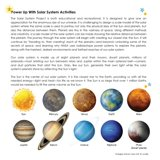
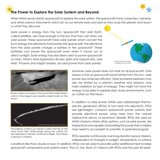
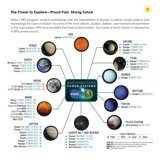
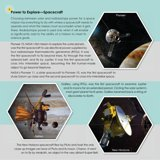
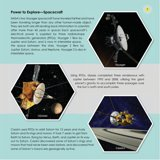
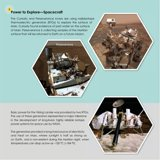
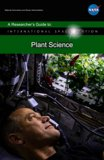
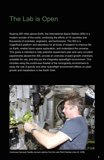
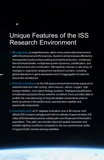
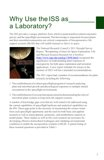
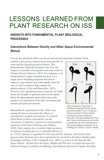
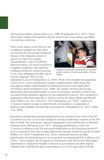
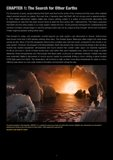
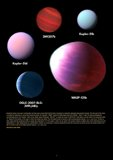
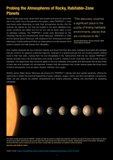
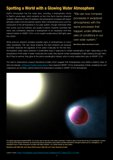
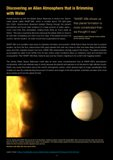
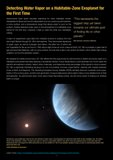
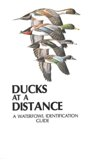
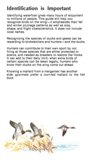
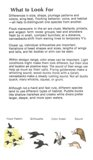
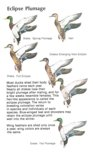
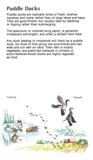

In [54]:
# 4 PDFs covering very different topics: space, biology, astronomy, and wildlife
pdf_files = {
    "PDF_01 - Solar System for Kids": "PDFs/PDF_01.pdf",
    "PDF_02 - NASA Plant Science": "PDFs/PDF_02.pdf",
    "PDF_03 - NASA Exoplanets": "PDFs/PDF_03.pdf",
    "PDF_04 - Identifying Ducks at distance": "PDFs/PDF_04.pdf",
}

pdf_pages = {}
pdf_embeddings = {}       # option 1: all pages, as images, in ONE embedding per PDF
pdf_text_embeddings = {}  # option 2: extracted text, as a document

for filename, path in pdf_files.items():
    pdf_bytes = load_file(path)
    pdf_pages[filename] = pdf_to_page_images(pdf_bytes)
    pdf_embeddings[filename] = get_embedding({"image": pdf_pages[filename]})
    pdf_text_embeddings[filename] = get_embedding(pdf_to_text(pdf_bytes), prompt_name="Document")

print(f"{len(pdf_embeddings)} PDFs embedded!\n")

# The pages the model sees
html = ""
for filename, pages in pdf_pages.items():
    html += f"<b>{filename}</b>: {len(pages)} pages<br>"
    html += "".join(f'<img src="{thumbnail(page, 160)}" height="110" style="margin:2px">' for page in pages)
    html += "<br>"
display(HTML(html))

In [55]:
# Our text query
query_text = "What document speaks about animals and identifying them?"
query_emb = get_embedding(query_text, prompt_name="SearchQuery")

# Compare the embedding of our text query against all PDF files
scores_pdf = []
for filename, emb in pdf_embeddings.items():
    score = cosine_similarity([query_emb], [emb])[0, 0]
    scores_pdf.append((filename, score))

scores_pdf = sorted(scores_pdf, key=lambda x: x[1], reverse=True)

print(f'\nQuery: "{query_text}"\n')
df_pdf1 = pd.DataFrame(scores_pdf, columns=["PDF file", "Cosine Similarity"])
df_pdf1.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])


Query: "What document speaks about animals and identifying them?"



PDF file,Cosine Similarity
PDF_04 - Identifying Ducks at distance,0.714178
PDF_03 - NASA Exoplanets,0.635242
PDF_01 - Solar System for Kids,0.623404
PDF_02 - NASA Plant Science,0.613979


And how does the cheaper **text extraction** option rank the same 4 PDFs for the same query?

In [56]:
scores_pdf_text = sorted(
    [(filename, cosine_similarity([query_emb], [emb])[0, 0]) for filename, emb in pdf_text_embeddings.items()],
    key=lambda x: x[1],
    reverse=True,
)

df_pdf1_text = pd.DataFrame(scores_pdf_text, columns=["PDF file (extracted text)", "Cosine Similarity"])
df_pdf1_text.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

PDF file (extracted text),Cosine Similarity
PDF_04 - Identifying Ducks at distance,0.704122
PDF_03 - NASA Exoplanets,0.618855
PDF_01 - Solar System for Kids,0.584780
PDF_02 - NASA Plant Science,0.569629


The duck identification guide wins clearly (0.71, vs 0.64 for the runner-up), even though the query never mentions ducks, and with no native PDF support at all: the model only saw 5 page images.

The text-extraction option produces exactly the same ranking (0.70 for the duck guide), so for these mostly-textual PDFs both approaches work. The page images are the ones that keep charts, photos, and layout, which matters for documents where the visuals carry the information.

#### PDF & audio

Let's push cross-modal search even further: can we use an audio clip to find the most relevant PDF document? Here we have a short audio recording about animals. Let's embed it and compare it against our PDF library (the page-image embeddings):

In [57]:
# Download and play our voice clip
audio_pdf_bytes = load_file("audios/audio_05.mp3")

Audio(data=audio_pdf_bytes, autoplay=False)

In [58]:
# Create the embedding of our voice clip
audio_pdf_emb = get_embedding(load_audio_16k(audio_pdf_bytes))

# Compare the embedding of our voice clip against all PDF files
scores_pdf_vs_audio = []
for filename, emb in pdf_embeddings.items():
    score = cosine_similarity([audio_pdf_emb], [emb])[0, 0]
    scores_pdf_vs_audio.append((filename, score))

scores_pdf_vs_audio = sorted(scores_pdf_vs_audio, key=lambda x: x[1], reverse=True)

print("Most similar PDFs to our voice clip:\n")
df_pdf2 = pd.DataFrame(scores_pdf_vs_audio, columns=["PDF file", "Cosine Similarity"])
df_pdf2.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Most similar PDFs to our voice clip:



PDF file,Cosine Similarity
PDF_04 - Identifying Ducks at distance,0.635945
PDF_03 - NASA Exoplanets,0.590249
PDF_01 - Solar System for Kids,0.555803
PDF_02 - NASA Plant Science,0.551909


The duck identification guide ranks first again (0.64), now from an audio clip about animals: audio → (rendered) PDF, two inputs with nothing in common on the surface.

#### PDF & PDF

We can also try to compare the embedding of "PDF_01 - Solar System for Kids" with the other three PDF files to see which one is a closest match to it:

In [59]:
# Using the embedding of "PDF_01 - Solar System for Kids" as our query
solar_system_emb = pdf_embeddings["PDF_01 - Solar System for Kids"]

# Compare the embedding of "PDF_01 - Solar System for Kids" against all PDF files
scores_pdf_vs_pdf = []
for filename, emb in pdf_embeddings.items():
    if filename != "PDF_01 - Solar System for Kids": # removing itself from comparison
        score = cosine_similarity([solar_system_emb], [emb])[0, 0]
        scores_pdf_vs_pdf.append((filename, score))

scores_pdf_vs_pdf = sorted(scores_pdf_vs_pdf, key=lambda x: x[1], reverse=True)

print("Most similar PDFs to 'PDF_01 - Solar System for Kids':\n")
df_pdf3 = pd.DataFrame(scores_pdf_vs_pdf, columns=["PDF file", "Cosine Similarity"])
df_pdf3.style.hide(axis="index").background_gradient(cmap="RdYlGn", subset=["Cosine Similarity"])

Most similar PDFs to 'PDF_01 - Solar System for Kids':



PDF file,Cosine Similarity
PDF_03 - NASA Exoplanets,0.820194
PDF_02 - NASA Plant Science,0.788820
PDF_04 - Identifying Ducks at distance,0.663223


The NASA Exoplanets document comes out on top (0.82), which makes sense, since both are about space, planets, and our solar system. The Plant Science guide comes second (0.79), ahead of the duck guide: plants have nothing to do with planets, but both documents come from NASA and share a similar style and vocabulary. And the duck identification guide? Last (0.66), since it lives in a completely different universe (pun intended).

## 📐 Extra: Changing the dimensions of the embeddings

EmbeddingGemma 2 is also trained with Matryoshka Representation Learning (MRL), which allows the model to produce useful embeddings at smaller dimensions. The difference is the starting point: the native size is **768** (not 3,072), and the supported truncations are **512, 256, and 128**.

MRL means the most important information is packed into the *first* dimensions, so "reducing the dimension" is just keeping the first `d` numbers of the vector. Two rules from the model card:

- **Re-normalize after truncating.** A slice of a unit-length vector is no longer unit-length. Skipping this doesn't raise any error; it just quietly degrades the ranking.
- **Queries and documents must share a dimension.** A 768-d query can't be scored against a 128-d index.

`encode()` can do both for you with `truncate_dim` and `normalize_embeddings=True`:
```python
query_emb = model.encode(query, truncate_dim=256, normalize_embeddings=True)
```

Smaller dimensions also mean significant memory savings. Assuming each dimension is stored as a 32-bit float (4 bytes), storing 1 million embeddings costs:

- **768 dims** → 768 × 4 × 1,000,000 ≈ **2.9 GB** (already 4× smaller than Gemini's 3,072-d default, 11.4 GB)
- **512 dims** → ≈ **1.9 GB**
- **256 dims** → ≈ **1.0 GB** (3× smaller)
- **128 dims** → ≈ **0.5 GB** (6× smaller)

The table below shows the scores Google reports in the model card for each dimension, on text (MTEB), code, image (MIEB), multimodal (MMEB), and audio (MSEB, MAEB) benchmarks. Notice that 512 and 256 stay close to 768, while 128 drops noticeably, especially on multimodal tasks (MMEB goes from 59.0 to 45.7). The model card's own advice: 128-d is best suited to text-only workloads.

| MRL Dimension | MTEB (multilingual) | MTEB (code) | MIEB (lite) | MMEB v2 | MSEB | MAEB |
|---|---|---|---|---|---|---|
| 768 | 61.36 | 78.68 | 65.67 | 59.01 | 69.54 | 49.87 |
| 512 | 61.17 | 77.24 | 65.34 | 58.38 | 69.18 | 49.76 |
| 256 | 60.41 | 76.18 | 64.16 | 56.24 | 66.76 | 49.13 |
| 128 | 57.89 | 71.41 | 59.97 | 45.65 | 56.71 | 47.28 |

Let's see how the cosine similarity scores and rankings change as we reduce the embedding dimensionality, using 'Surf' as our query. Unlike the original guide, we don't need to call the model again for each size: we truncate the 768-d vectors we already have, and re-normalize. First, a quick check that this gives the same result as asking the model directly with `truncate_dim`:

In [60]:
def truncate(embedding: np.ndarray, dim: int) -> np.ndarray:
    """Keep the first `dim` dimensions and re-normalize to unit length."""
    truncated = embedding[..., :dim]
    return truncated / np.linalg.norm(truncated, axis=-1, keepdims=True)

# Sanity check: manual truncation vs. asking the model for 128 dims directly
direct_128 = get_embedding(videos["Surf"], processing_kwargs=VIDEO_KWARGS, truncate_dim=128, normalize_embeddings=True)
print(f"Max difference: {np.abs(direct_128 - truncate(video_embeddings['Surf'], 128)).max():.6f}")

video_embeddings_dimensionality = {}
for dimensionality in [768, 512, 256, 128]:
    video_embeddings_dimensionality[dimensionality] = {
        filename: truncate(emb, dimensionality) for filename, emb in video_embeddings.items()
    }

print(f"Embeddings generated for {len(video_embeddings_dimensionality)} different dimensions")

Max difference: 0.001301
Embeddings generated for 4 different dimensions


In [61]:
results = {}
for dimensionality in [768, 512, 256, 128]:
  surf_emb = video_embeddings_dimensionality[dimensionality]["Surf"]
  scores = [
      (filename, cosine_similarity([surf_emb], [emb])[0, 0])
      for filename, emb in video_embeddings_dimensionality[dimensionality].items()
      if filename != "Surf"
  ]
  results[dimensionality] = dict(sorted(scores, key=lambda x: x[1], reverse=True))

# Score table
df_scores = pd.DataFrame(results).round(4)
df_scores.index.name = "Video file"
df_scores.columns = [f"{d} dims" for d in df_scores.columns]

# Rank table — rank 1 = most similar
df_ranks = df_scores.rank(ascending=False).astype(int)

print("Cosine Similarity Scores:")
display(df_scores.style.background_gradient(cmap="RdYlGn", axis=None))

print("\nRankings per Dimensionality:")
display(df_ranks.style.background_gradient(cmap="RdYlGn_r", axis=None))

Cosine Similarity Scores:


,768 dims,512 dims,256 dims,128 dims
Video file,,,,
Waves,0.705600,0.714900,0.739400,0.813000
Dog,0.633100,0.650200,0.662900,0.773300
Forest,0.612000,0.616700,0.657500,0.760000
Food,0.610300,0.622200,0.656700,0.785400



Rankings per Dimensionality:


,768 dims,512 dims,256 dims,128 dims
Video file,,,,
Waves,1,1,1,1
Dog,2,2,2,3
Forest,3,4,3,4
Food,4,3,4,2


Two things to notice:
- **Waves stays first at every size, and Dog stays second down to 256 dimensions.** Forest and Food are practically tied for third place from 768 to 256 dimensions (at most 0.006 apart), so they trade places back and forth. At 128 dimensions Food jumps to second, which matches the model card's warning that 128 dimensions degrade multimodal quality.
- The **scores go up** as we cut dimensions (Waves: 0.71 → 0.81). With fewer dimensions there's less room for vectors to point in different directions, so everything looks more similar. Compare rankings, not raw scores.

The sanity check also passed: manual truncation + re-normalization matches `truncate_dim=128` up to `bfloat16` rounding (max difference ≈ 0.001).

## 🪶 Extra: Loading only the encoders you need

This one has no equivalent in the Gemini guide, because there you never see the model. EmbeddingGemma 2's vision and audio encoders are separate components, so a text-only application (a RAG over documents, say) can skip them entirely. With `sentence-transformers`, that's done with `config_kwargs`:

| Active modalities | `config_kwargs` | Size |
|---|---|---|
| Text only | `{"vision_config": None, "audio_config": None}` | 270M |
| Text + image | `{"audio_config": None}` | 440M |
| Text + audio | `{"vision_config": None}` | 570M |
| Everything | `{}` | 740M |

Let's load the text-only version and check that it produces the **same text embeddings** as the full model:

In [62]:
memory_before = torch.cuda.memory_allocated() if device == "cuda" else 0

text_only_model = SentenceTransformer(
    MODEL,
    device=device,
    model_kwargs={"torch_dtype": dtype},
    config_kwargs={"vision_config": None, "audio_config": None},
)

print(f"Full model:      {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters")
print(f"Text-only model: {sum(p.numel() for p in text_only_model.parameters()) / 1e6:.0f}M parameters")
if device == "cuda":
    print(f"Extra GPU memory taken by the text-only model: {(torch.cuda.memory_allocated() - memory_before) / 1e9:.2f} GB")

sentence = "EmbeddingGemma 2 runs on a laptop."
full_emb = model.encode(sentence, prompt_name="SentenceSimilarity")
text_only_emb = text_only_model.encode(sentence, prompt_name="SentenceSimilarity")
print(f"\nCosine similarity between both embeddings of the same sentence: {cosine_similarity([full_emb], [text_only_emb])[0, 0]:.4f}")

# The vision encoder is really gone:
try:
    text_only_model.encode(to_pil(king_image_bytes))
except ValueError as error:
    print(f"\nEmbedding an image with the text-only model fails: {error}")
print(f"(Even so, text_only_model.supports('image') says {text_only_model.supports('image')}, because the processor is the same.)")

del text_only_model
if device == "cuda":
    torch.cuda.empty_cache()

Full model:      744M parameters
Text-only model: 271M parameters
Extra GPU memory taken by the text-only model: 0.54 GB

Cosine similarity between both embeddings of the same sentence: 1.0000



Embedding an image with the text-only model fails: Image features were requested, but the model was initialized without a vision_config. Cannot process images without a vision tower and vision embedder.
(Even so, text_only_model.supports('image') says True, because the processor is the same.)


The text-only model has **271M parameters** instead of 744M, takes about a third of the GPU memory (≈0.54 GB), and produces the **same** text embeddings as the full model (cosine 1.0000). Asking it to embed an image fails with a clear error. One gotcha: `model.supports("image")` still says `True`, because the processor is the same; you only find out when you actually try.

## 🏁 Recap: did the model find what we expected?

To wrap up, here is every experiment in one table: the answer we'd expect, what EmbeddingGemma 2 returned in this run (computed from the cells above, so it always reflects the run you're looking at), and the **margin** between its first and second places. Below ~0.01, a result is practically a coin toss, even when it's right.

The last column is just a reference: the top result in the [Gemini Embedding 2 guide](https://github.com/fabriciocarraro/Gemini-Embedding-2-Complete-Guide), for the experiments that use exactly the same inputs there.

In [63]:
def top_and_margin(scores, name=lambda item: item[0]):
    """Top result of a ranking and its lead over the runner-up (the score is the last element of each tuple)."""
    ranked = sorted(scores, key=lambda item: item[-1], reverse=True)
    return name(ranked[0]), ranked[0][-1] - ranked[1][-1]

words = list(df_similarity.index)
word_pairs = [(f"{a} ↔ {b}", df_similarity.loc[a, b]) for i, a in enumerate(words) for b in words[i + 1:]]
post_number = lambda item: item[0].split(":")[0]  # "Post 1: Text-only about..." → "Post 1"
file_label = lambda item: item[0].split(" - ")[1]  # "audio_01 - ambulance" → "ambulance"

experiments = [
    # (experiment, expected answer(s), EmbeddingGemma 2 ranking, label function, top result in the Gemini guide or None if inputs differ)
    ("Most similar pair among man/woman/dog/electricity", ["man ↔ woman"], word_pairs, None, "man ↔ woman"),
    ("king − man + woman", ["queen"], scores_op1, None, "queen*"),
    ("Washington, D.C. − USA + Brazil", ["Brasilia"], scores_op2, None, "Brasilia"),
    ("King image → closest word", ["king"], scores_king_img, None, "king"),
    ("King image → closest image", ["crown"], scores_king_vs_images, None, "crown"),
    ("King image − crown image → closest image", ["man"], scores_op3, None, "man"),
    ("Tweet about the Gemini AI model → closest post", ["Post 1", "Post 2"], scores_combined, post_number, "Post 1"),
    ("'Emergency vehicle siren' text → audio", ["ambulance"], scores_audio, file_label, None),
    ("Scary-forest voice clip → audio", ["wolf"], scores_audio_vs_audio, file_label, "wolf"),
    ("Ambulance image → audio", ["ambulance"], scores_img_vs_audio, file_label, "ambulance"),
    ("'Animals for my documentary' text → video", ["Dog"], scores_video, None, "Dog"),
    ("Animal voice clip → video", ["Dog"], scores_video_vs_audio, None, "Dog"),
    ("Surf video → video", ["Waves"], scores_video_vs_video, None, "Waves"),
    ("'Animals and identifying them' text → PDF", ["Ducks"], scores_pdf, file_label, "Ducks"),
    ("Animal voice clip → PDF", ["Ducks"], scores_pdf_vs_audio, file_label, "Ducks"),
    ("Solar System PDF → PDF", ["NASA Exoplanets"], scores_pdf_vs_pdf, file_label, "NASA Exoplanets"),
]

recap = []
for experiment, expected, scores, name, gemini in experiments:
    gemma, margin = top_and_margin(scores, name or (lambda item: item[0]))
    found = "✅" if any(answer.lower() in gemma.lower() for answer in expected) else "❌"
    recap.append((experiment, " or ".join(expected), gemma, found, margin, gemini or "— (different input)"))

df_recap = pd.DataFrame(recap, columns=["Experiment", "Expected", "EmbeddingGemma 2", "Found?", "Margin", "Gemini guide"])
print(f"Expected answer found in {(df_recap['Found?'] == '✅').sum()} of {len(df_recap)} experiments")
print("* Top non-source word in the Gemini guide (its table showed 'king' first because the source words were not excluded).")
df_recap.style.hide(axis="index").format({"Margin": "{:.3f}"})

Expected answer found in 15 of 16 experiments
* Top non-source word in the Gemini guide (its table showed 'king' first because the source words were not excluded).


Experiment,Expected,EmbeddingGemma 2,Found?,Margin,Gemini guide
Most similar pair among man/woman/dog/electricity,man ↔ woman,man ↔ woman,✅,0.023,man ↔ woman
king − man + woman,queen,queen,✅,0.095,queen*
"Washington, D.C. − USA + Brazil",Brasilia,Brasilia,✅,0.045,Brasilia
King image → closest word,king,king,✅,0.066,king
King image → closest image,crown,crown,✅,0.132,crown
King image − crown image → closest image,man,man,✅,0.108,man
Tweet about the Gemini AI model → closest post,Post 1 or Post 2,Post 2,✅,0.017,Post 1
'Emergency vehicle siren' text → audio,ambulance,ambulance,✅,0.028,— (different input)
Scary-forest voice clip → audio,wolf,wolf,✅,0.052,wolf
Ambulance image → audio,ambulance,rain,❌,0.040,ambulance


**The expected answer comes out on top in 15 of the 16 experiments**: word arithmetic, image matching and arithmetic, combined text + image posts, text and voice queries over audio and video, and every PDF experiment (through page images!). The one miss is **photo → sound effect** (the ambulance image finds the rain), where hubness gets in the way.

Check the "Margin" column too: a ✅ with a tiny margin is not much of a win. The closest call is the posts row (0.017), and its answer depends on the prompt.

**Bottom line:** EmbeddingGemma 2 puts text, images, audio, and video in a single 768-dimensional space, on a laptop GPU, with no API key. Compared with a hosted API, you need a few extra steps: decode audio to 16 kHz, render PDFs as images, pick the right task prompt, and raise the vision budget when quality matters more than speed. What you get in return: privacy, offline use, no per-call cost, small vectors, and an open model you can fine-tune or ship on-device.